# WP01 Graf kavramları ve küçük ilaç–protein ağı

**05.11.2026 · Çalıştırılmış öğretici notebook.** Hücrelerin altındaki tablolar ve grafikler gerçek yürütme çıktılarıdır. Sıra: kavram → oyuncak örnek → gerçek legacy alt graf → test → yorum.

Bu paket veri temizleme veya J01 kohortu oluşturma paketi değildir. Gerçek örnek eski izinli `ilac_protein_eslesmesi_v6.csv` ilişkilerinin sınırlı bir gösterimidir. Kaynak kayıtları yeniden biyolojik doğrulamadan geçirilmiş sayılmaz. Yeni veri, model eğitimi, `kalite_skoru` veya yan etki hedef kenarı kullanılmaz.

**Çalıştırma:** Proje içinden Jupyter ile açıp “Restart Kernel and Run All” seçin. Notebook proje kökünü kendisi bulur; internet gerekmez. Kaynak CSV'nin tamamı yerelde saklanmadı; yalnız görseldeki 10 ilişkinin kaynak satırı belirtilmiş eğitim örneği JSON olarak tutuldu.

In [1]:
from pathlib import Path
import sys, json, platform
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'AGENTS.md').exists())
sys.path.insert(0, str(ROOT/'scripts'))
from wp01_graphs import toy_graph, real_graph, metrics, summary, draw, real_positions, interactive
OUT = ROOT/'reports/qa/WP01'; OUT.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame({'bileşen':['Python','NetworkX','pandas'], 'sürüm':[platform.python_version(),nx.__version__,pd.__version__]}))

,bileşen,sürüm
0,Python,3.11.3
1,NetworkX,3.6.1
2,pandas,3.0.3


## 1 Düğüm ve kenar

Graf $G=(V,E)$ bir düğüm kümesi ve bu düğümler arasındaki kenarlardan oluşur. Düğüm bir varlığı, kenar tanımlanmış bir ilişkiyi temsil eder. Aşağıdaki **sentetik** grafın A–B–C üçgeni, C–D uzantısı ve bağlantısız E düğümü var. A ile B arasındaki çizgi bir kayıt, geometrik uzunluğu ise çizim tercihidir.

Tezde düğüm ilaç veya protein; kenar kaynakta bildirilen ilaç→hedef ilişkisi olabilir. İlaç ve protein kimliklerini farklı öneklerle saklamak aynı metnin yanlışlıkla aynı düğüm olmasını engeller.

C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,
C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,


,düğüm,komşular
0,A,"[B, C]"
1,B,"[A, C]"
2,C,"[A, B, D]"
3,D,[C]
4,E,[]


,uç 1,uç 2
0,A,B
1,A,C
2,B,C
3,C,D


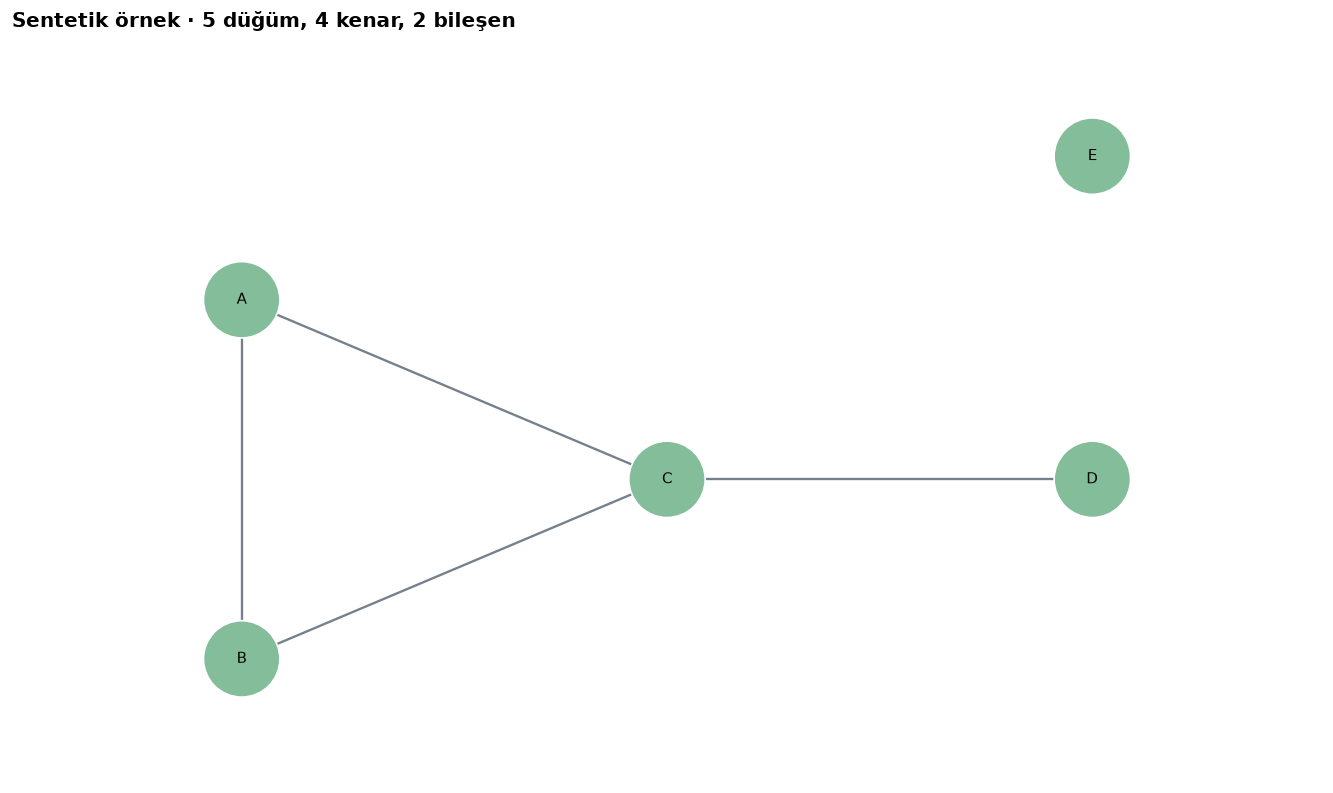

,nodes,edges,components_undirected,isolates,density_directed_or_undirected,average_degree_undirected,clustering_undirected
0,5,4,2,1,0.4,1.6,0.466667


In [2]:
G = toy_graph()
display(pd.DataFrame({'düğüm':list(G), 'komşular':[sorted(G.neighbors(n)) for n in G]}))
display(pd.DataFrame(G.edges(), columns=['uç 1','uç 2']))
pos = {'A':(0,1),'B':(0,0),'C':(1,.5),'D':(2,.5),'E':(2,1.4)}
draw(G,'01_nodes_edges','Sentetik örnek · 5 düğüm, 4 kenar, 2 bileşen',pos=pos)
display(summary(G))

**Okuma:** E'nin listede olup kenarı olmaması onu izole düğüm yapar. Veride ilişki bulunmaması biyolojik ilişkinin imkânsız olduğu anlamına gelmez. Kaynakta hiç kaydı olmayan ilaçlar yalnız kenar tablosundan kurulan grafın içine kendiliğinden girmez.

## 2 Yönlü ve yönsüz graf

`nx.Graph` ilişkiyi simetrik işler: A–B varsa B'nin komşusu A'dır. `nx.DiGraph` için A→B, B→A'yı yaratmaz. **Ardıl** dışarı giden, **öncül** içeri gelen komşudur. Buradaki ok yönü ilişki şemasıdır; biyolojik nedensellik veya fiziksel sinyal akışı kanıtı değildir.

,düğüm,öncüller,ardıllar,giriş derecesi,çıkış derecesi
0,A,[],[B],0,1
1,B,[A],[C],1,1
2,C,[B],[],1,0


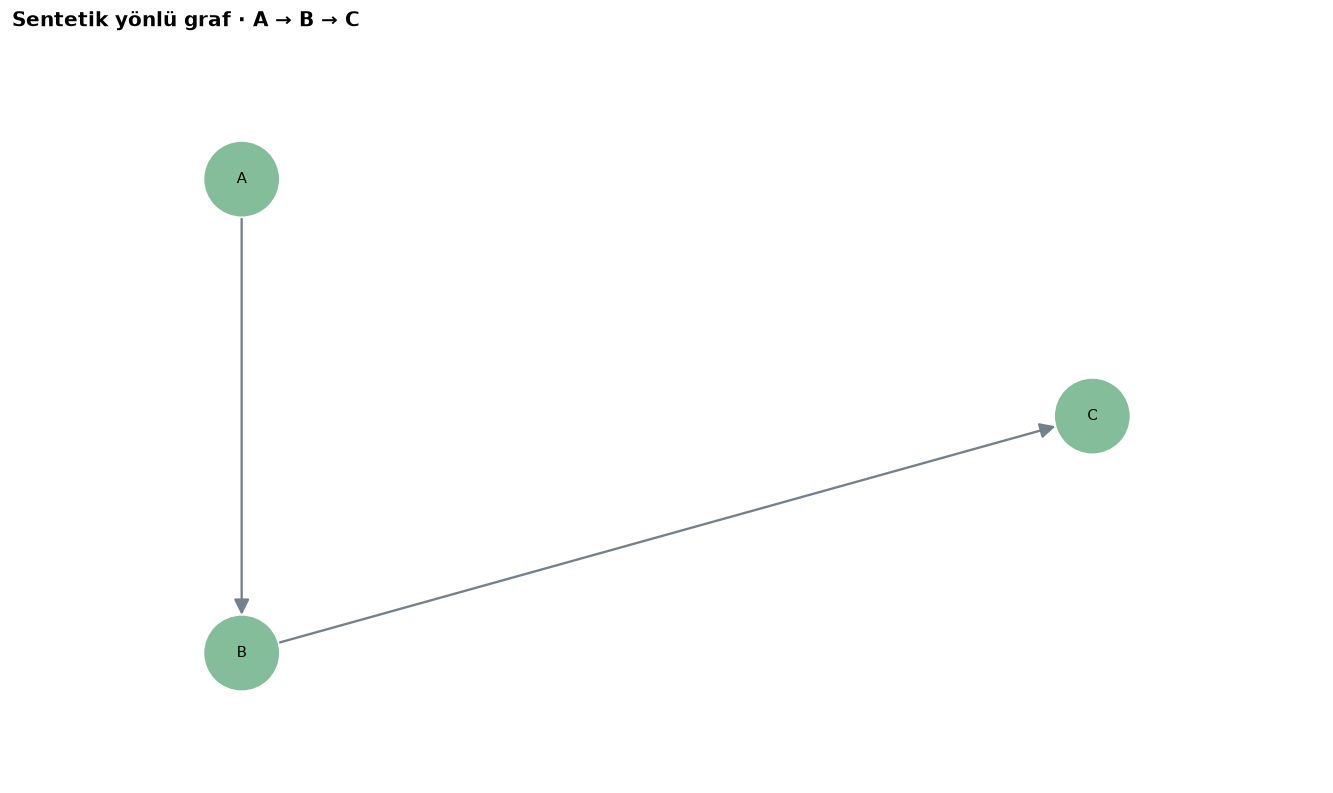

,sorgu,var mı
0,A→C yolu,True
1,C→A yolu,False
2,yönsüz C–A yolu,True


In [3]:
D = nx.DiGraph([('A','B'),('B','C')])
display(pd.DataFrame([{'düğüm':n,'öncüller':list(D.predecessors(n)),'ardıllar':list(D.successors(n)),
                      'giriş derecesi':D.in_degree(n),'çıkış derecesi':D.out_degree(n)} for n in D]))
draw(D,'02_direction','Sentetik yönlü graf · A → B → C',pos={n:pos[n] for n in D})
display(pd.DataFrame({'sorgu':['A→C yolu','C→A yolu','yönsüz C–A yolu'],
                     'var mı':[nx.has_path(D,'A','C'),nx.has_path(D,'C','A'),nx.has_path(D.to_undirected(),'C','A')]}))

**Tez açısından:** İlaç→protein şemasında protein ardılı yok diye protein bağlantısız değildir; giriş kenarları vardır. Merkezilik hesaplarken yönlü ilişkiyi mi yoksa yönsüz bağlantı izdüşümünü mü kullandığımızı açıkça seçmeliyiz.

## 3 Komşuluk derece ve 1-hop 2-hop

Bir düğümün komşuları doğrudan bağlı olduğu düğümlerdir. Derece bunların sayısıdır (burada basit, kendine kenarsız graf). Yönsüz grafın dereceler toplamı $2|E|$ olur. “Tam 2-hop” uzaklığı iki olanları; `ego_graph(radius=2)` ise merkez dahil uzaklığı **en çok** iki olanları verir.

C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,
C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,


,düğüm,A’ya uzaklık,derece
0,A,0,2
1,B,1,2
2,C,1,3
3,D,2,1
4,E,erişilemiyor,0


,küme,düğümler
0,tam 1-hop,"[B, C]"
1,tam 2-hop,[D]
2,en çok 2-hop,"[A, B, C, D]"


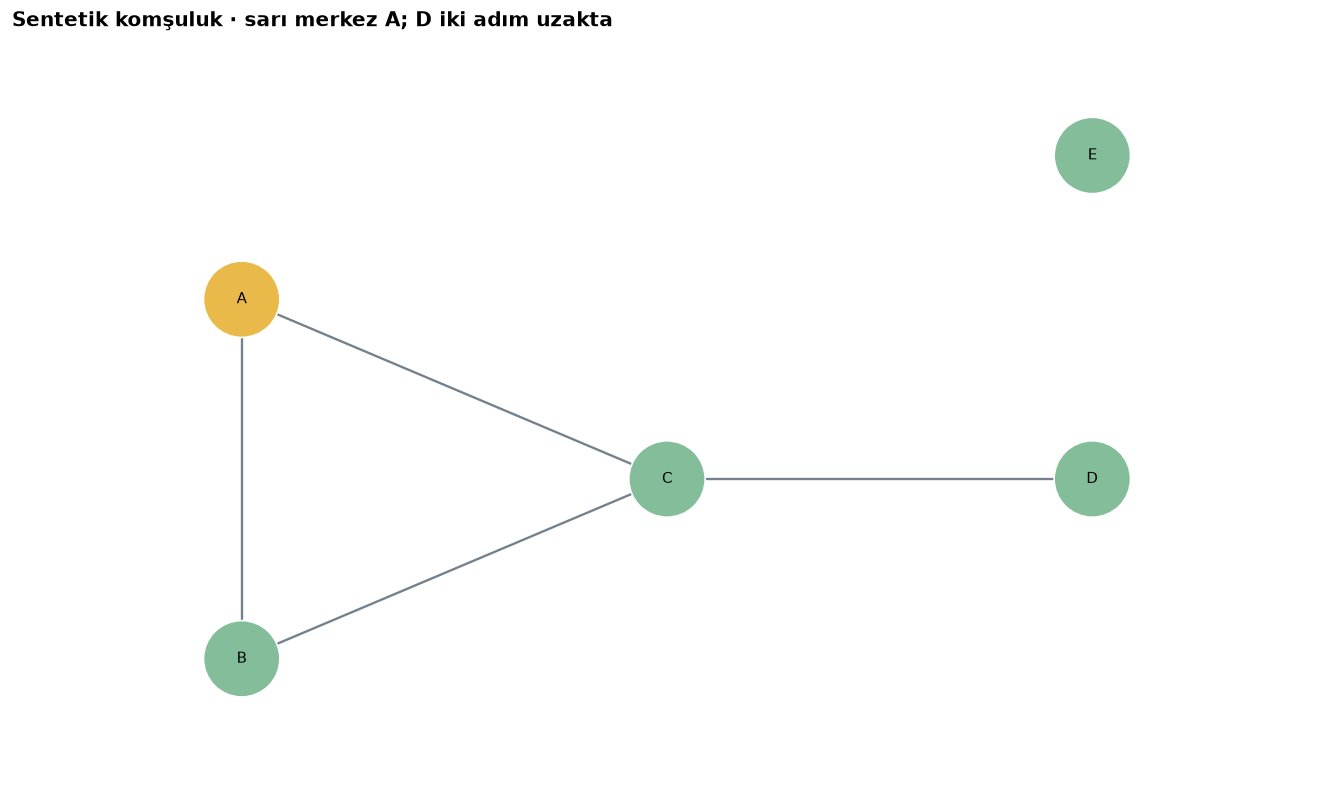

In [4]:
distance = nx.single_source_shortest_path_length(G,'A',cutoff=2)
display(pd.DataFrame([{'düğüm':n,'A’ya uzaklık':distance.get(n,'erişilemiyor'),'derece':G.degree(n)} for n in G]))
display(pd.DataFrame({'küme':['tam 1-hop','tam 2-hop','en çok 2-hop'],
                     'düğümler':[[n for n,d in distance.items() if d==1],[n for n,d in distance.items() if d==2],list(nx.ego_graph(G,'A',radius=2))]}))
draw(G,'03_hops','Sentetik komşuluk · sarı merkez A; D iki adım uzakta',pos=pos,highlight=['A'])
assert sum(dict(G.degree()).values()) == 2*G.number_of_edges()

## 4 Ağırlık güç ve uzaklık

Ağırlığın anlamı açıkça tanımlanmalıdır. Aşağıdaki sentetik ağırlık **mesafe/maliyet**: A–B=1, B–C=1, A–C=5. Ağırlıksız en kısa yol tek kenarlı A–C; mesafe toplamını en aza indiren yol A–B–C'dir. Daha büyük güven/etkileşim skoru daha uzun mesafe anlamına gelmez; böyle bir dönüşüm gerekçesiz yapılamaz. Gerçek alt grafımızda doğrulanmış kenar ağırlığı bulunmadığı için ağırlık kullanılmaz.

Out[0]: {'A': (0, 1), 'B': (0, 0), 'C': (1, 0.5)}


C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,
C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,


,başlangıç,bitiş,distance
0,A,B,1
1,A,C,5
2,B,C,1


,yöntem,A–C yolu,uzunluk
0,kenar sayısı,"[A, C]",1
1,mesafe toplamı,"[A, B, C]",2


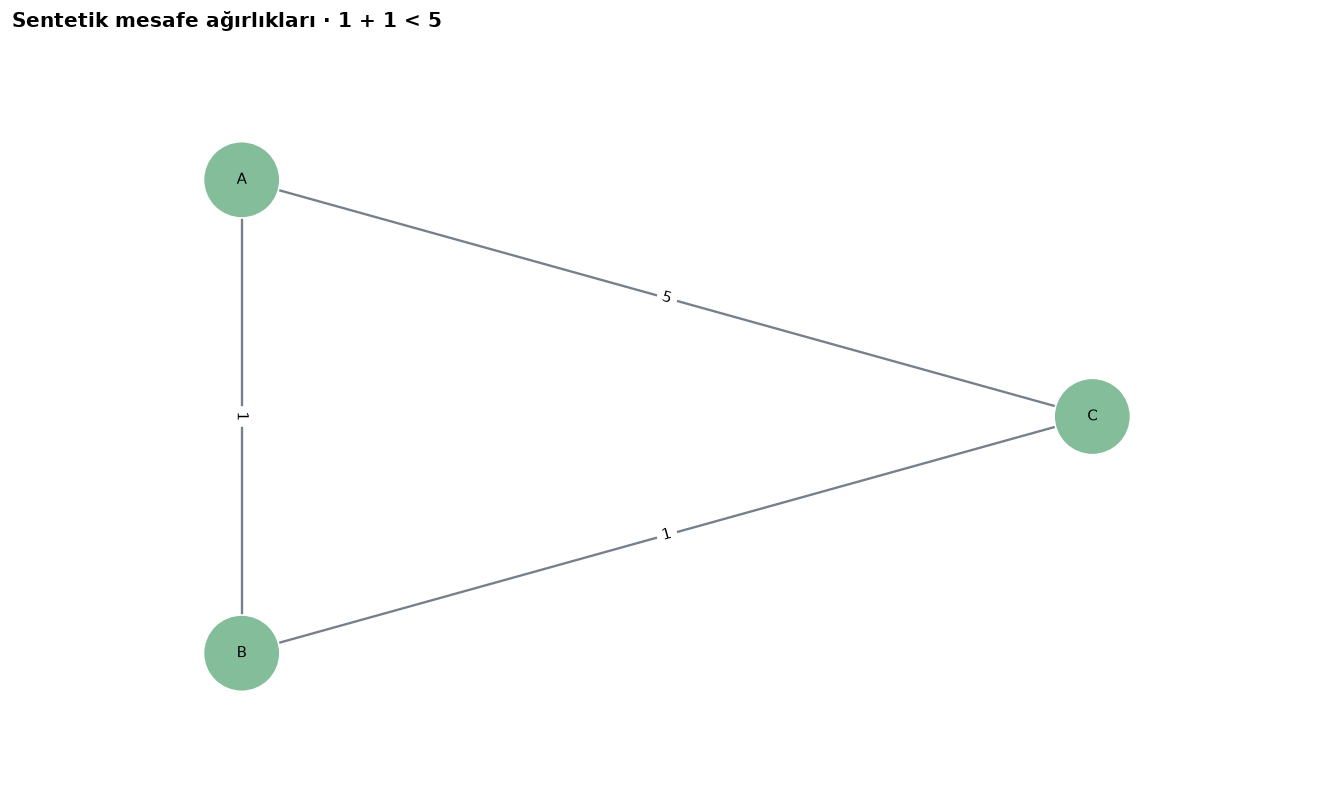

In [5]:
W = nx.Graph()
W.add_weighted_edges_from([('A','B',1),('B','C',1),('A','C',5)],weight='distance')
display(pd.DataFrame([{'başlangıç':a,'bitiş':b,**v} for a,b,v in W.edges(data=True)]))
display(pd.DataFrame({'yöntem':['kenar sayısı','mesafe toplamı'],
                     'A–C yolu':[nx.shortest_path(W,'A','C'),nx.shortest_path(W,'A','C',weight='distance')],
                     'uzunluk':[nx.shortest_path_length(W,'A','C'),nx.shortest_path_length(W,'A','C',weight='distance')]}))
draw(W,'04_weights','Sentetik mesafe ağırlıkları · 1 + 1 < 5',pos={n:pos[n] for n in W},edge_labels=nx.get_edge_attributes(W,'distance'))

## 5 Merkezilik

**Derece merkeziliği** $k/(N-1)$ doğrudan bağlantıyı ölçer. **Aradalık** (betweenness), en kısa yolların ne kadarının düğümden geçtiğini gösterir; uç düğümler sayılmaz ve eşit yollar paylaştırılır. **Yakınlık** (closeness), erişilen düğümlere uzaklıkla ilişkilidir. Burada NetworkX'in kopuk bileşenleri erişilebilir oranla düzelten `wf_improved=True` seçeneği kullanılır.

Bu üç soru farklıdır: “Kaç bağlantısı var?”, “Kaç en kısa yol üzerinde?”, “Diğerlerine ne kadar yakın?”. Yüksek değer biyolojik önem veya yan etki riski ölçümü değildir; kaynak kapsamından ve düğüm seçiminden etkilenir.

,node,label,kind,degree,degree_centrality,betweenness,closeness_WF
0,C,C,toy,3,0.75,0.3333,0.7500
1,A,A,toy,2,0.50,0.0000,0.5625
2,B,B,toy,2,0.50,0.0000,0.5625
3,D,D,toy,1,0.25,0.0000,0.4500
4,E,E,toy,0,0.00,0.0000,0.0000


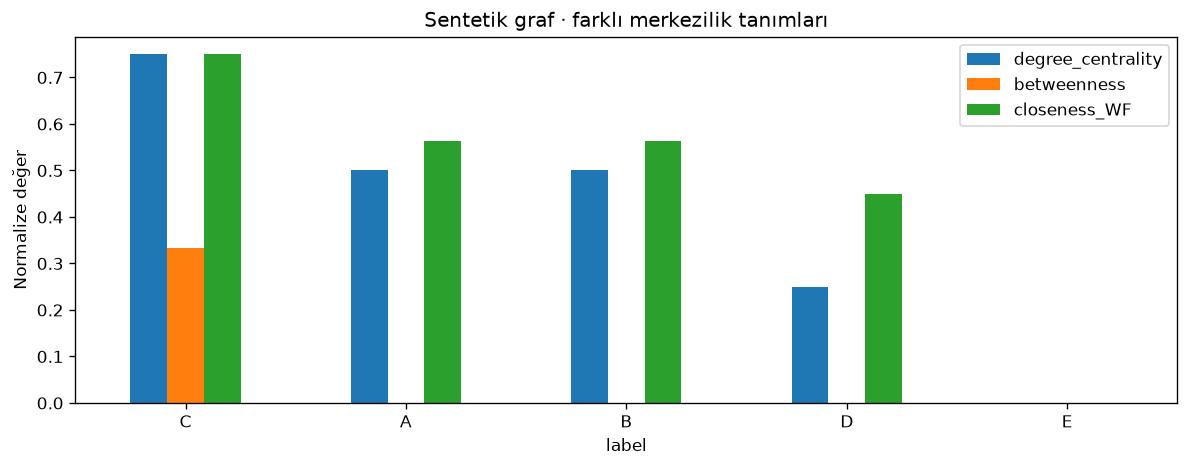

In [6]:
toy_metrics = metrics(G)
display(toy_metrics.round(4))
ax=toy_metrics.set_index('label')[['degree_centrality','betweenness','closeness_WF']].plot.bar(figsize=(10,4),rot=0)
ax.set_title('Sentetik graf · farklı merkezilik tanımları'); ax.set_ylabel('Normalize değer')
plt.tight_layout(); plt.savefig(ROOT/'reports/figures/WP01/05_centrality.png',dpi=160); plt.show()

**Okuma:** C, üçgeni D'ye bağladığı için aradalığı yükselir; E sıfır değer alır. İlaç–protein gibi iki parçalı graflarda ilaç ve protein rollerini ayrı karşılaştırmak gerekir. Buradaki derece normalizasyonu tüm N−1 düğüme göredir; karşı parçanın büyüklüğüne göre normalize edilmiş özel bipartit merkezilik değildir.

## 6 Alt graf ve bağlı bileşen

Seçilen düğümler arasındaki tüm mevcut kenarları korursak **indüklenmiş alt graf** elde ederiz. Kenar alt grafı yalnız seçilen kenarları içerir. Bir bağlı bileşende her iki düğüm arasında yol vardır; bileşenler arasında yol yoktur. Merkezilik alt graf içinde yeniden hesaplanınca değişebilir.

Out[0]: {'A': (0, 1), 'B': (0, 0), 'C': (1, 0.5)}


C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,
C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,


,bileşen,düğümler
0,1,"[A, B, C, D]"
1,2,[E]


,ölçüm,değer
0,C tüm grafta derece,3.0
1,C üçgen alt grafta derece,2.0
2,tüm graf yoğunluk,0.4
3,üçgen yoğunluk,1.0


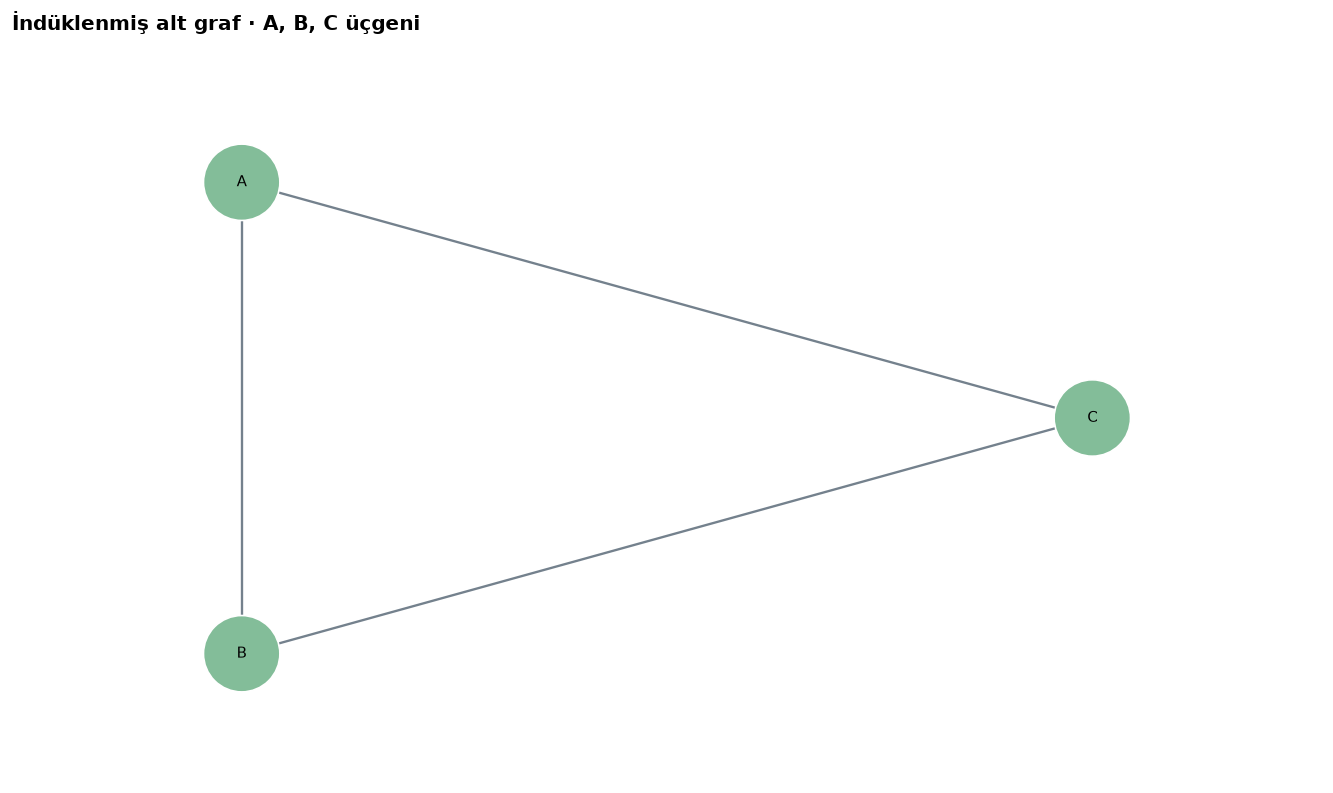

In [7]:
H = G.subgraph(['A','B','C']).copy()
display(pd.DataFrame({'bileşen':range(1,nx.number_connected_components(G)+1),
                     'düğümler':[sorted(c) for c in nx.connected_components(G)]}))
display(pd.DataFrame({'ölçüm':['C tüm grafta derece','C üçgen alt grafta derece','tüm graf yoğunluk','üçgen yoğunluk'],
                     'değer':[G.degree('C'),H.degree('C'),nx.density(G),nx.density(H)]}))
draw(H,'06_subgraph','İndüklenmiş alt graf · A, B, C üçgeni',pos={n:pos[n] for n in H})

## 7 İzinli gerçek veriden küçük ilaç–protein alt grafı

Kaynak: `ilac_protein_eslesmesi_v6.csv` (Drive, 153×5). Dört ilaç **öğretici amaçla** seçildi: Ciprofloxacin, Norfloxacin, Levofloxacin, Amoxicillin. Yalnız Humans, tabloda açık yazılı H. influenzae KW20/Rd ve Helicobacter pylori organizma metinlerindeki ilişkiler gösterildi. Seçim; ortak hedefler, tek ilaca bağlı hedef ve ayrı bileşen görülmesi içindir. Bir J01 kohortu veya tüm hedef ağı değildir.

Örnek JSON sadece seçilen 10 ilişkinin kaynak satırlarını ve provenansı saklar. CSV'nin tamamı indirilip dosya olarak kaydedilmedi. Organizma adı içeren protein ilişkilerini göstermek yeni organizma STRING veri seti kullanmak anlamına gelmez; burada PPI yoktur.

In [8]:
sample = json.loads((ROOT/'reports/qa/wp01_graph_sample.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'kaynak':sample['source_url'],'son değişiklik':sample['source_modified_time'],
                       'kaynak satır':sample['source_rows'],'seçili ilişki':len(sample['relations'])}]))
relations = pd.DataFrame(sample['relations'])
display(relations)
display(pd.DataFrame({'alan':relations.columns,'boş hücre':[(relations[c].isna() | relations[c].astype(str).str.strip().eq('')).sum() for c in relations],
                      'kayıt sayısı':len(relations)}))
R = real_graph(sample); U = R.to_undirected()
display(summary(R).round(4))
display(pd.DataFrame([{'ilaç':R.nodes[n]['label'],'giriş':R.in_degree(n),'çıkış':R.out_degree(n)} for n in R if R.nodes[n]['kind']=='drug']))

,kaynak,son değişiklik,kaynak satır,seçili ilişki
0,https://drive.google.com/file/d/1SkXYX0w4k76yx...,2026-05-14T05:37:21.845Z,153,10


,DrugBank_ID,Drug_Name,UniProt_ID,Gene_Name,Organizma,source_row
0,DB00537,Ciprofloxacin,P43702,parC,Haemophilus influenzae (strain ATCC 51907 / DS...,44
1,DB00537,Ciprofloxacin,P43700,gyrA,Haemophilus influenzae (strain ATCC 51907 / DS...,45
2,DB00537,Ciprofloxacin,P11388,TOP2A,Humans,49
3,DB00537,Ciprofloxacin,Q12809,KCNH2,Humans,50
4,DB01059,Norfloxacin,P43700,gyrA,Haemophilus influenzae (strain ATCC 51907 / DS...,104
5,DB01059,Norfloxacin,P43702,parC,Haemophilus influenzae (strain ATCC 51907 / DS...,105
6,DB01059,Norfloxacin,P11388,TOP2A,Humans,107
7,DB01060,Amoxicillin,Q8L103,PBP1,Helicobacter pylori,110
8,DB01137,Levofloxacin,P43700,gyrA,Haemophilus influenzae (strain ATCC 51907 / DS...,121
9,DB01137,Levofloxacin,P43702,parC,Haemophilus influenzae (strain ATCC 51907 / DS...,122


,alan,boş hücre,kayıt sayısı
0,DrugBank_ID,0,10
1,Drug_Name,0,10
2,UniProt_ID,0,10
3,Gene_Name,0,10
4,Organizma,0,10
5,source_row,0,10


,nodes,edges,components_undirected,isolates,density_directed_or_undirected,average_degree_undirected,clustering_undirected
0,9,10,2,0,0.1389,2.2222,0.0


,ilaç,giriş,çıkış
0,Ciprofloxacin,0,4
1,Norfloxacin,0,3
2,Amoxicillin,0,1
3,Levofloxacin,0,2


**Şema:** `drug:DB…` ve `protein:UniProt…` farklı düğüm tipleri, `targets_legacy` tek kenar tipidir. Düğüm etiketleri okunabilirlik içindir; birleştirme anahtarı gen adı değildir. Aynı gen adı farklı organizmalarda aynı protein anlamına gelmez. Eski kaynak kaydı, doğrulanmış bağlanma gücü veya klinik etki olarak yorumlanmaz.

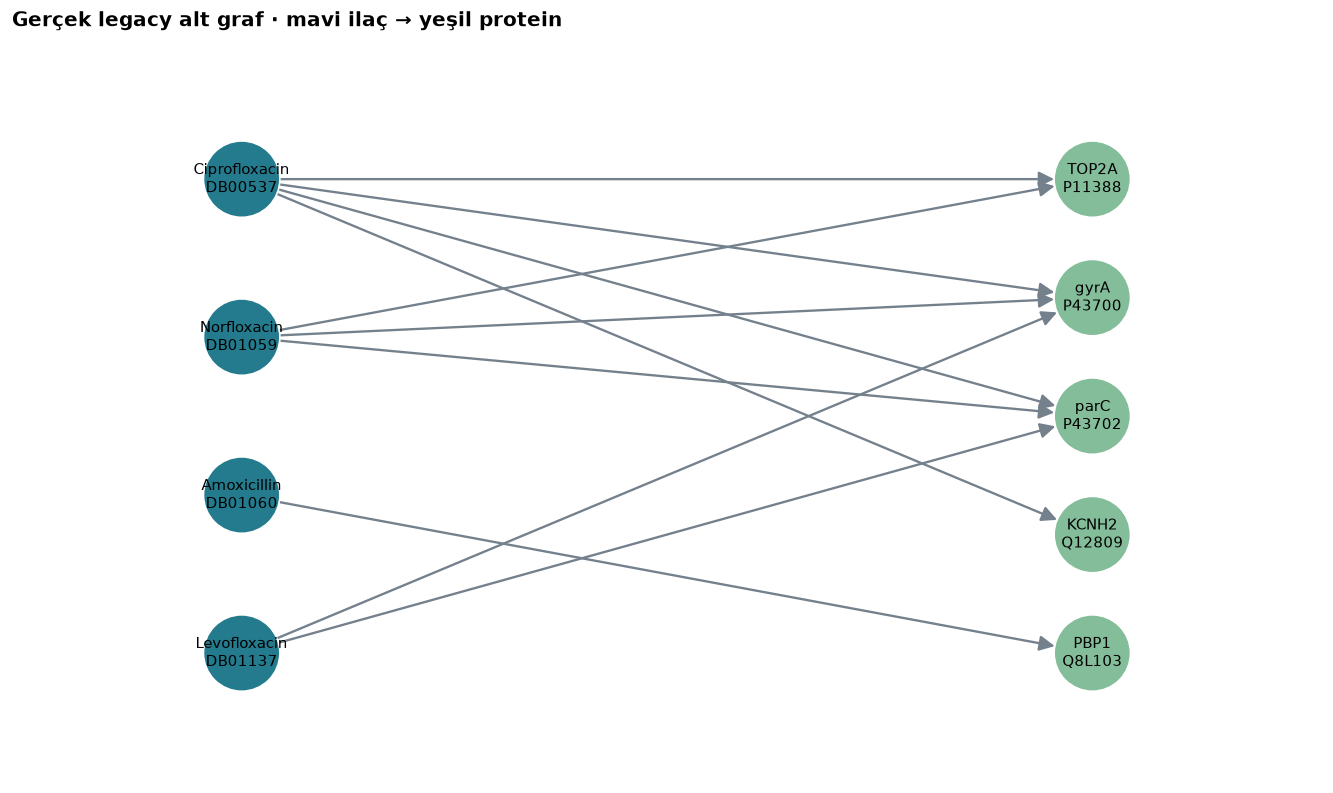

,bileşen,düğüm,kenar,etiketler
0,1,7,9,"Ciprofloxacin, Norfloxacin, Levofloxacin, TOP2..."
1,2,2,1,"Amoxicillin, PBP1"


In [9]:
rp = real_positions(R)
labels = {n:R.nodes[n]['label']+'\n'+R.nodes[n]['identifier'] for n in R}
draw(R,'07_real_graph','Gerçek legacy alt graf · mavi ilaç → yeşil protein',pos=rp,labels=labels)
component_table = pd.DataFrame([{'bileşen':i,'düğüm':len(c),'kenar':U.subgraph(c).number_of_edges(),
                                 'etiketler':', '.join(R.nodes[n]['label'] for n in sorted(c))}
                                for i,c in enumerate(sorted(nx.connected_components(U),key=len,reverse=True),1)])
display(component_table)

**Grafiğin anlamı:** Ortak proteinler birden çok ilaca bağlanır. Amoxicillin bu seçimde yalnız PBP1 (Q8L103) ilişkisiyle ayrı bileşendedir. Bu görünüm ilacın gerçekte yalnız bir hedefi olduğunu kanıtlamaz; filtre ve eski tablo kapsamının sonucudur. Grafın iki parçalı yapısı nedeniyle üçgen/clustering=0 beklenir; bu değer “biyoloji seyrek” sonucunu tek başına vermez.

Özet tablosundaki yoğunluk yönlü graf için $10/(9·8)=0,1389$ değeridir. Yönsüz izdüşümde $10/36=0,2778$; yalnız izin verilen ilaç–protein çiftlerini payda alırsak $10/(4·5)=0,5$ olur. Paydaları farklı bu ölçümler birbirinin yerine kullanılamaz.

,node,label,kind,degree,degree_centrality,betweenness,closeness_WF
0,drug:DB00537,Ciprofloxacin,drug,4,0.500,0.2440,0.5625
1,drug:DB01059,Norfloxacin,drug,3,0.375,0.0655,0.4500
2,protein:P43700,gyrA,protein,3,0.375,0.0952,0.5000
3,protein:P43702,parC,protein,3,0.375,0.0952,0.5000
4,drug:DB01137,Levofloxacin,drug,2,0.250,0.0119,0.3750
5,protein:P11388,TOP2A,protein,2,0.250,0.0238,0.4091
6,drug:DB01060,Amoxicillin,drug,1,0.125,0.0000,0.1250
7,protein:Q12809,KCNH2,protein,1,0.125,0.0000,0.3462
8,protein:Q8L103,PBP1,protein,1,0.125,0.0000,0.1250


,düğüm,tür,öncüller,ardıllar
0,Ciprofloxacin,drug,[],"[protein:P43702, protein:P43700, protein:P1138..."
1,parC,protein,"[drug:DB00537, drug:DB01059, drug:DB01137]",[]
2,gyrA,protein,"[drug:DB00537, drug:DB01059, drug:DB01137]",[]
3,TOP2A,protein,"[drug:DB00537, drug:DB01059]",[]
4,KCNH2,protein,[drug:DB00537],[]
5,Norfloxacin,drug,[],"[protein:P43700, protein:P43702, protein:P11388]"
6,Amoxicillin,drug,[],[protein:Q8L103]
7,PBP1,protein,[drug:DB01060],[]
8,Levofloxacin,drug,[],"[protein:P43700, protein:P43702]"


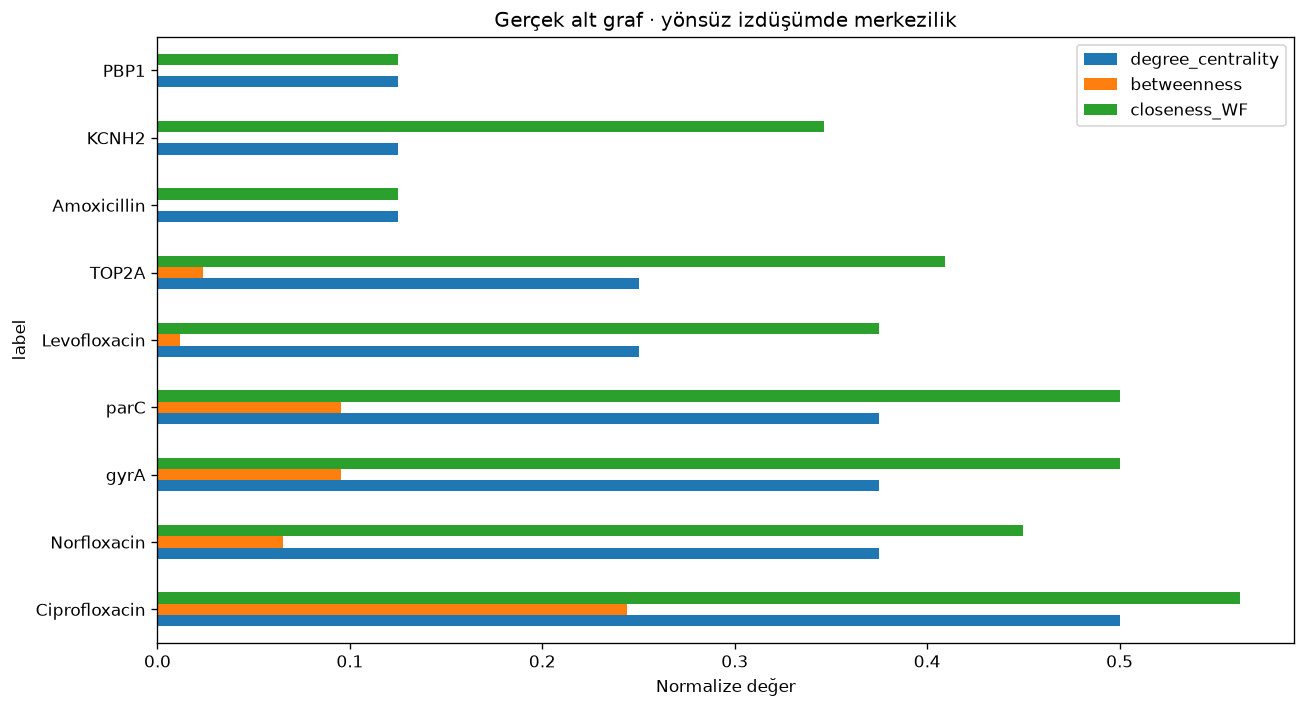

In [10]:
real_metrics = metrics(R)
display(real_metrics.round(4))
display(pd.DataFrame([{'düğüm':R.nodes[n]['label'],'tür':R.nodes[n]['kind'],
                       'öncüller':list(R.predecessors(n)),'ardıllar':list(R.successors(n))} for n in R]))
ax=real_metrics.set_index('label')[['degree_centrality','betweenness','closeness_WF']].plot.barh(figsize=(11,6))
ax.set_title('Gerçek alt graf · yönsüz izdüşümde merkezilik');ax.set_xlabel('Normalize değer')
plt.tight_layout();plt.savefig(ROOT/'reports/figures/WP01/08_real_metrics.png',dpi=160);plt.show()
real_metrics.to_csv(OUT/'node_metrics.csv',index=False,encoding='utf-8-sig')
component_table.to_csv(OUT/'components.csv',index=False,encoding='utf-8-sig')

**Tez açısından:** Derece ve aradalığı yüksek düğümler bu alt grafın bağlantı düzenini özetler. Graf küçültülünce sıralama değişebilir. Bu değerleri kalite skoru yerine kullanıp model girdisi yapmıyoruz. İlaç ve proteinleri farklı biyolojik rolleriyle okumak gerekir; gözlenen derece farmakolojik etki büyüklüğü değildir.

## 8 Gerçek veride 1-hop ve 2-hop

Yönlü ilaç→protein grafında bir ilacın ardılları hedefleridir. Proteinlerden dışarı giden kenar olmadığı için yönlü iki adımla başka ilaca ulaşılmaz. **Yönsüz izdüşümde** ilaç–protein–ilaç yolu ortak hedef paylaşımını gösterebilir. Bu, PPI veya ilaç–ilaç etkileşim kanıtı değildir.

Out[0]: 
{'drug:DB00537': (0, 1.0),
 'protein:P43702': (1, 0.5),
 'protein:P43700': (1, 0.75),
 'protein:P11388': (1, 1.0),
 'protein:Q12809': (1, 0.25),
 'drug:DB01059': (0, 0.6666666666666667),
 'drug:DB01137': (0, 0.0)}


C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,
C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\scripts\wp01_graphs.py:52: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(g,pos,arrows=g.is_directed(),node_size=2100,arrowstyle='-|>',arrowsize=19,


,ID,etiket,tür,hop
0,drug:DB00537,Ciprofloxacin,drug,0
1,protein:P43702,parC,protein,1
2,protein:P43700,gyrA,protein,1
3,protein:P11388,TOP2A,protein,1
4,protein:Q12809,KCNH2,protein,1
5,drug:DB01059,Norfloxacin,drug,2
6,drug:DB01137,Levofloxacin,drug,2


,sorgu,düğüm sayısı
0,yönlü en çok 2-hop,5
1,yönsüz en çok 2-hop,7


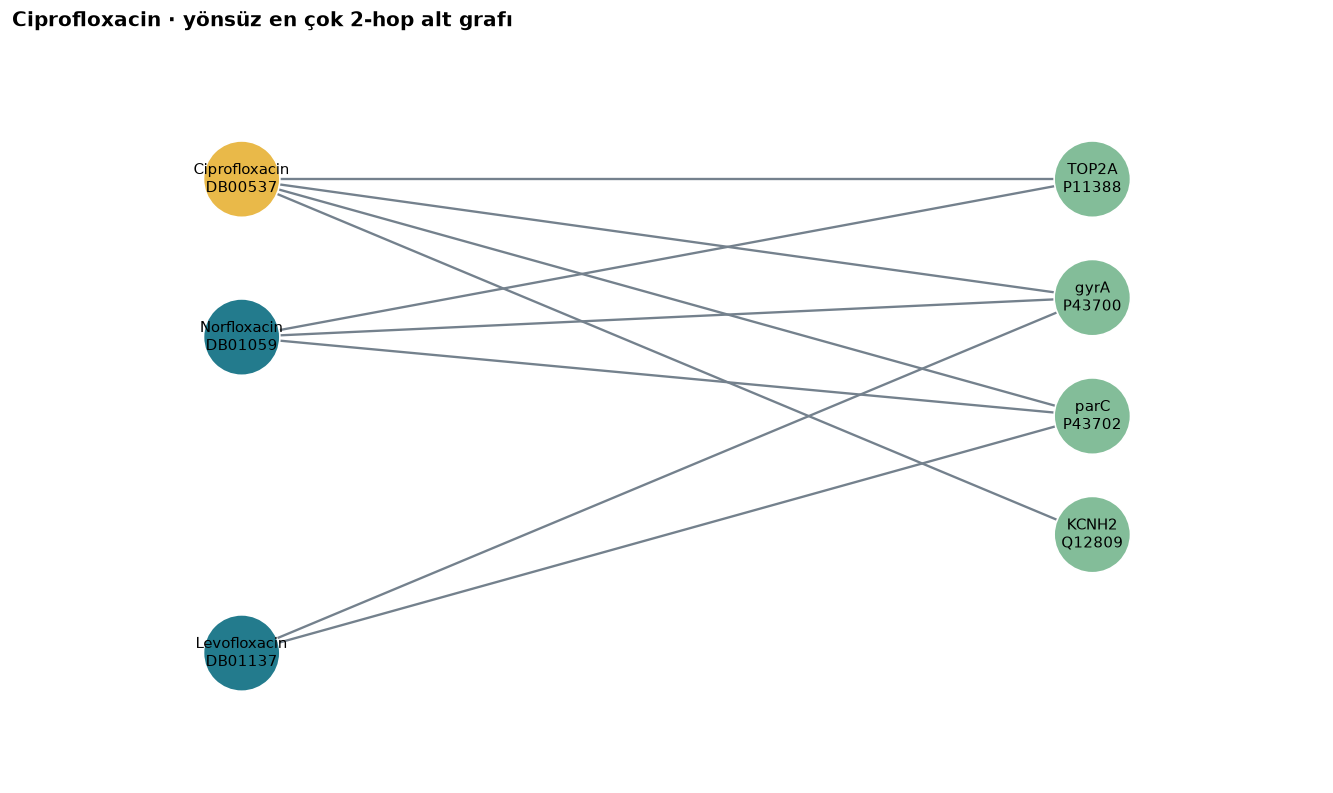

In [11]:
center='drug:DB00537'
ds=nx.single_source_shortest_path_length(U,center,cutoff=2)
display(pd.DataFrame([{'ID':n,'etiket':R.nodes[n]['label'],'tür':R.nodes[n]['kind'],'hop':d} for n,d in ds.items()]))
display(pd.DataFrame({'sorgu':['yönlü en çok 2-hop','yönsüz en çok 2-hop'],
                     'düğüm sayısı':[len(nx.ego_graph(R,center,radius=2)),len(nx.ego_graph(U,center,radius=2))]}))
ego=U.subgraph(ds).copy()
draw(ego,'09_real_ego','Ciprofloxacin · yönsüz en çok 2-hop alt grafı',pos={n:rp[n] for n in ego},
     labels={n:labels[n] for n in ego},highlight=[center])

## 9 NetworkX ve HeteroData fikri

NetworkX'te türleri düğüm/kenar metadata'sında tutuyoruz. İleride `HeteroData` aynı fikri ayrı tür depoları ve tamsayı indeksleriyle temsil eder: `drug`, `protein`, `(drug, targets, protein)`. Aşağıdaki indeks tablosu yalnız temsil örneğidir; PyG grafı veya model oluşturulmaz. İleride yan etki ilişkileri hedef olacağı için test hedeflerinin eğitim grafına eklenmemesi ayrıca sınanmalıdır.

In [12]:
drug_nodes=sorted(n for n in R if R.nodes[n]['kind']=='drug')
protein_nodes=sorted(n for n in R if R.nodes[n]['kind']=='protein')
di={n:i for i,n in enumerate(drug_nodes)};pi={n:i for i,n in enumerate(protein_nodes)}
display(pd.DataFrame([{'kaynak indeksi':di[a],'hedef indeksi':pi[b],'ilişki':'drug → targets → protein',
                       'ilaç':a,'protein':b} for a,b in R.edges]))
html_path=ROOT/'reports/figures/WP01/real_graph_interactive.html'
interactive(R,rp,html_path)
display(Markdown('**İnteraktif çıktı:** Fareyle düğüm kimliği ve organizmasını inceleyin; yakınlaştırma, kaydırma ve PNG dışa aktarma araçları var. HTML kendi Plotly paketini içerir, internet istemez.'))
display(FileLink(str(html_path)))

,kaynak indeksi,hedef indeksi,ilişki,ilaç,protein
0,0,2,drug → targets → protein,drug:DB00537,protein:P43702
1,0,1,drug → targets → protein,drug:DB00537,protein:P43700
2,0,0,drug → targets → protein,drug:DB00537,protein:P11388
3,0,3,drug → targets → protein,drug:DB00537,protein:Q12809
4,1,1,drug → targets → protein,drug:DB01059,protein:P43700
5,1,2,drug → targets → protein,drug:DB01059,protein:P43702
6,1,0,drug → targets → protein,drug:DB01059,protein:P11388
7,2,4,drug → targets → protein,drug:DB01060,protein:Q8L103
8,3,1,drug → targets → protein,drug:DB01137,protein:P43700
9,3,2,drug → targets → protein,drug:DB01137,protein:P43702


**İnteraktif çıktı:** Fareyle düğüm kimliği ve organizmasını inceleyin; yakınlaştırma, kaydırma ve PNG dışa aktarma araçları var. HTML kendi Plotly paketini içerir, internet istemez.

C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\figures\WP01\real_graph_interactive.html

## 10 Doğrulama ve öğrenme özeti

Kontroller aşağıda çalışır. Kaynak kapsamı: 153 satırlık tarihsel tablodan 10 seçilmiş ilişki; dört ilaç ve beş protein. Merkezilik yönsüz ve ağırlıksız izdüşümde hesaplandı. Gerçek kenarlara rastgele ağırlık atanmadı.

Kendinizi sınayın: C neden aradalıkta yükseldi? Ağırlık güven skoru olsaydı en kısa yol hesabına doğrudan verilebilir miydi? İki ilaç ortak hedefe sahipse bu bir PPI kenarı mıdır? Bu notebook'un ilgili hücreleri cevapları tablolarla gösterir.

In [13]:
assert len(R)==9 and R.number_of_edges()==10
assert nx.is_bipartite(U) and nx.number_connected_components(U)==2
assert all(R.nodes[a]['kind']=='drug' and R.nodes[b]['kind']=='protein' for a,b in R.edges)
assert all('weight' not in attrs and 'kalite_skoru' not in attrs for _,_,attrs in R.edges(data=True))
assert sum(dict(U.degree()).values())==2*U.number_of_edges()
assert len(nx.ego_graph(R,center,radius=2))==5
assert len(nx.ego_graph(U,center,radius=2))==7
assert not nx.has_path(U,center,'drug:DB01060')
assert metrics(G).set_index('node').loc['C','betweenness'] > 0
result={'nodes':len(R),'edges':R.number_of_edges(),'components':nx.number_connected_components(U),
        'drug_nodes':len(drug_nodes),'protein_nodes':len(protein_nodes),'source_id':sample['source_id'],
        'networkx':nx.__version__,'checks':'passed','scope':'WP01 only'}
(OUT/'graph_summary.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([result]))
display(Markdown('**WP01 tamamlandı.** Kaynaklar değiştirilmedi; kullanıcı onayı olmadan WP02 başlatılmaz.'))

,nodes,edges,components,drug_nodes,protein_nodes,source_id,networkx,checks,scope
0,9,10,2,4,5,1SkXYX0w4k76yxwHZbLydz6Q5Aj9gA7cz,3.6.1,passed,WP01 only


**WP01 tamamlandı.** Kaynaklar değiştirilmedi; kullanıcı onayı olmadan WP02 başlatılmaz.